In [ ]:
#Correlation Power Analysis


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [28]:
#loading traces and hypothesis
data = np.load(
    "results/preprocessing/preprocessed_data.npz"
)

traces = data["traces"]

print(traces.shape)

hypothesis_data = np.load(
    "results/leakage_model/hd_hypotheses.npz"
)

H0 = hypothesis_data["byte_0"]

print(H0.shape)

(100000, 200)
(100000, 256)


In [34]:
#correlation function
def correlation_matrix(H, T):

    H = H.astype(np.float64)
    T = T.astype(np.float64)

    H_centered = H - H.mean(
        axis=0,
        keepdims=True
    )

    T_centered = T - T.mean(
        axis=0,
        keepdims=True
    )

    numerator = H_centered.T @ T_centered

    H_norm = np.sqrt(
        np.sum(H_centered ** 2, axis=0)
    )

    T_norm = np.sqrt(
        np.sum(T_centered ** 2, axis=0)
    )

    denominator = (
        H_norm[:, None]
        * T_norm[None, :]
    )

    return numerator / denominator

(256, 200)
Best key: 0x91
Peak sample: 49
Correlation: -0.13203417570655135
Absolute correlation: 0.13203417570655135


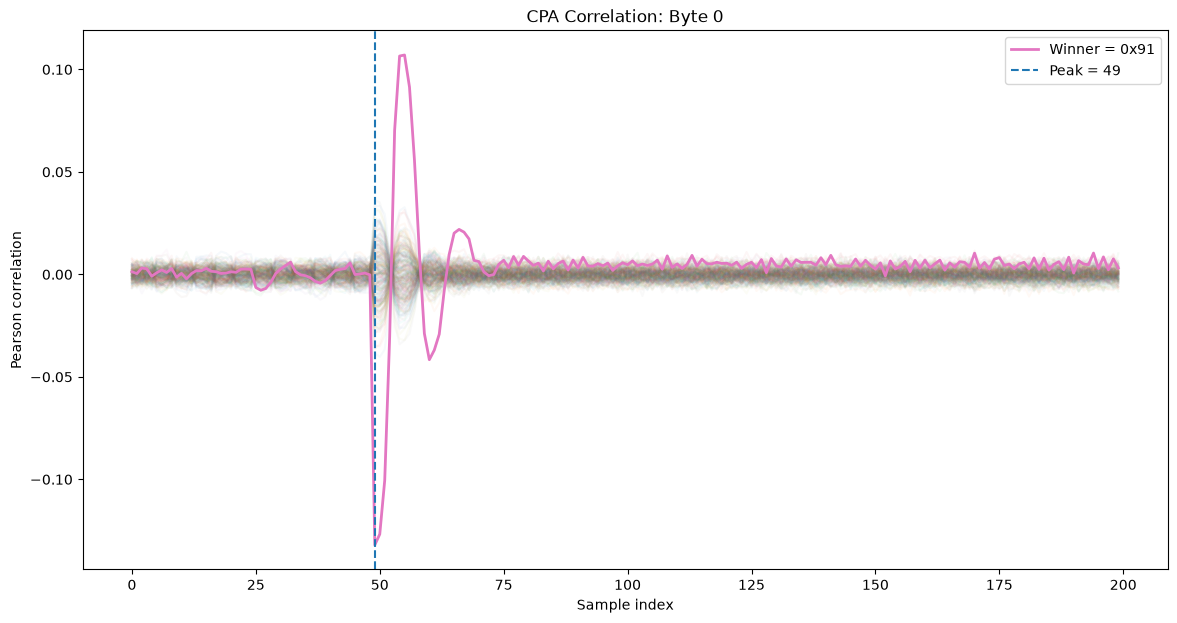

In [35]:
R0 = correlation_matrix(
    H0,
    traces
)
print(R0.shape)

scores0 = np.max(
    np.abs(R0),
    axis=1
)

best_key0 = int(
    np.argmax(scores0)
)

peak_sample0 = int(
    np.argmax(
        np.abs(R0[best_key0])
    )
)

peak_corr0 = R0[
    best_key0,
    peak_sample0
]

print(f"Best key: 0x{best_key0:02X}")
print("Peak sample:", peak_sample0)
print("Correlation:", peak_corr0)
print("Absolute correlation:", abs(peak_corr0))

plt.figure(figsize=(14, 7))

for k in range(256):
    plt.plot(
        R0[k],
        alpha=0.04
    )

plt.plot(
    R0[best_key0],
    linewidth=2,
    label=f"Winner = 0x{best_key0:02X}"
)

plt.axvline(
    peak_sample0,
    linestyle="--",
    label=f"Peak = {peak_sample0}"
)

plt.xlabel("Sample index")
plt.ylabel("Pearson correlation")
plt.title("CPA Correlation: Byte 0")
plt.legend()

plt.show()

In [36]:
#top 10 candidates
ranking = np.argsort(
    scores0
)[::-1]

for rank, key in enumerate(
    ranking[:10],
    start=1
):

    print(
        f"Rank {rank}: "
        f"0x{key:02X} "
        f"| |r| = {scores0[key]:.6f}"
    )

Rank 1: 0x91 | |r| = 0.132034
Rank 2: 0x46 | |r| = 0.040293
Rank 3: 0xA1 | |r| = 0.036380
Rank 4: 0x4D | |r| = 0.036243
Rank 5: 0xB7 | |r| = 0.035127
Rank 6: 0x14 | |r| = 0.033446
Rank 7: 0x6C | |r| = 0.032151
Rank 8: 0x58 | |r| = 0.031830
Rank 9: 0xD5 | |r| = 0.029934
Rank 10: 0x03 | |r| = 0.028799


In [33]:
#CPA on 16 bytes
results = []
correlation_matrices = {}

for byte_index in range(16):

    print(f"Attacking byte {byte_index}...")

    H = hypothesis_data[
        f"byte_{byte_index}"
    ]

    R = correlation_matrix(
        H,
        traces
    )

    correlation_matrices[
        byte_index
    ] = R

    scores = np.max(
        np.abs(R),
        axis=1
    )

    best_key = int(
        np.argmax(scores)
    )

    peak_sample = int(
        np.argmax(
            np.abs(R[best_key])
        )
    )

    peak_corr = float(
        R[best_key, peak_sample]
    )

    results.append({
        "byte": byte_index,
        "key": best_key,
        "peak_sample": peak_sample,
        "correlation": peak_corr,
        "abs_correlation": abs(peak_corr)
    })

    print(
        f"  Key = 0x{best_key:02X}, "
        f"sample = {peak_sample}, "
        f"|r| = {abs(peak_corr):.6f}"
    )

Attacking byte 0...
  Key = 0x91, sample = 49, |r| = 0.132034
Attacking byte 1...
  Key = 0x2D, sample = 180, |r| = 0.014437
Attacking byte 2...
  Key = 0xC0, sample = 49, |r| = 0.144975
Attacking byte 3...
  Key = 0x4E, sample = 147, |r| = 0.012726
Attacking byte 4...
  Key = 0xE3, sample = 49, |r| = 0.119641
Attacking byte 5...
  Key = 0xA4, sample = 31, |r| = 0.012477
Attacking byte 6...
  Key = 0xCE, sample = 49, |r| = 0.126033
Attacking byte 7...
  Key = 0x50, sample = 74, |r| = 0.012229
Attacking byte 8...
  Key = 0x99, sample = 49, |r| = 0.124603
Attacking byte 9...
  Key = 0x06, sample = 129, |r| = 0.014839
Attacking byte 10...
  Key = 0x38, sample = 49, |r| = 0.131500
Attacking byte 11...
  Key = 0x48, sample = 72, |r| = 0.016352
Attacking byte 12...
  Key = 0x20, sample = 49, |r| = 0.132874
Attacking byte 13...
  Key = 0xDE, sample = 55, |r| = 0.014893
Attacking byte 14...
  Key = 0x3A, sample = 49, |r| = 0.118693
Attacking byte 15...
  Key = 0xEB, sample = 111, |r| = 0.01432

In [10]:
#fake key construction
results_df = pd.DataFrame(results)

fake_key = bytes(
    results_df["key"].tolist()
)

print("Recovered fake round-10 key:")
print(
    " ".join(
        f"{b:02X}"
        for b in fake_key
    )
)

Recovered fake round-10 key:
91 2D C0 4E E3 A4 CE 50 99 06 38 48 20 DE 3A EB


In [11]:
#saving result
Path("results/cpa").mkdir(
    parents=True,
    exist_ok=True
)

results_df.to_csv(
    "results/cpa/fake_key_results.csv",
    index=False
)

with open(
    "results/cpa/fake_round10_key.txt",
    "w"
) as f:

    f.write(
        fake_key.hex()
    )

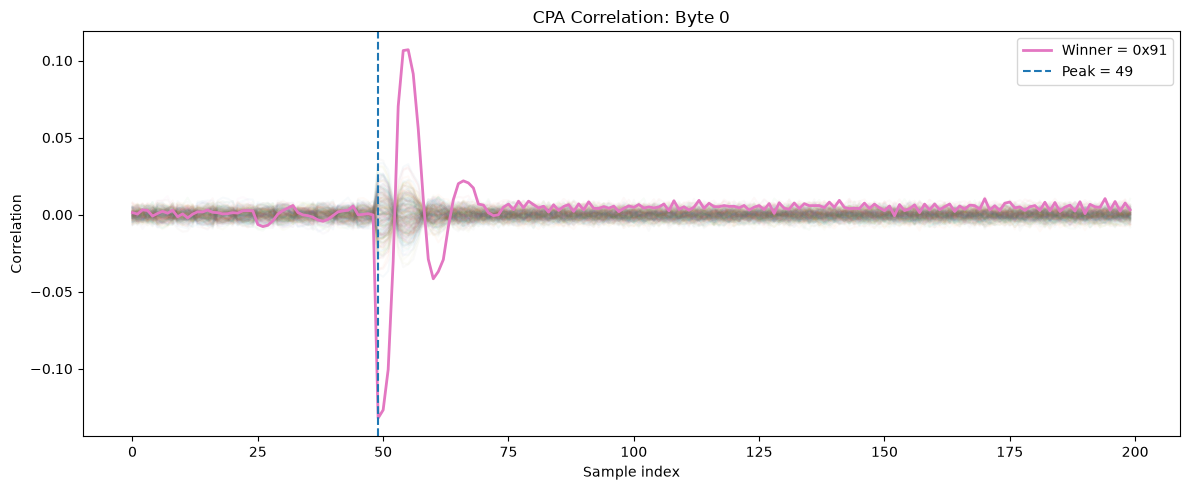

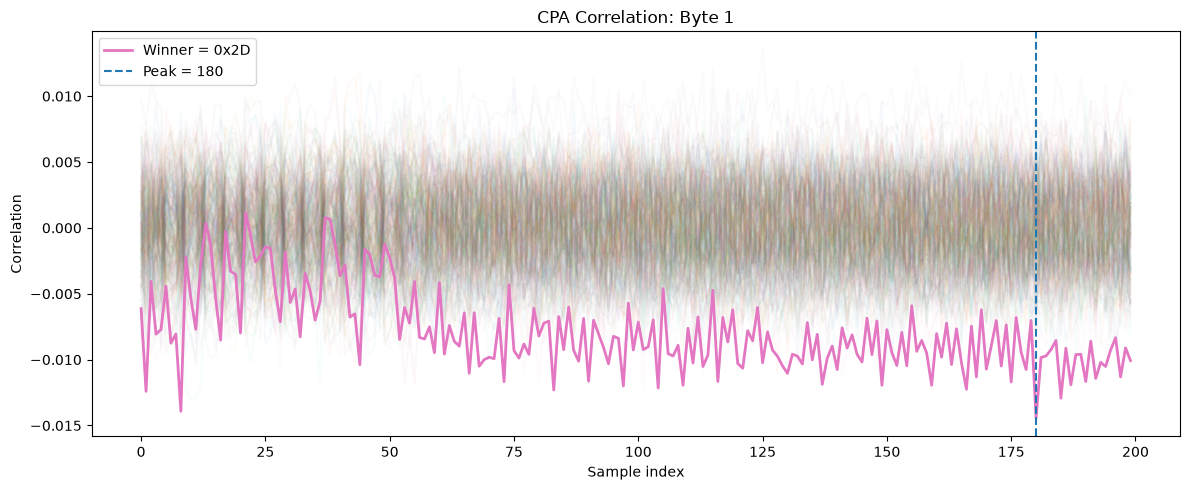

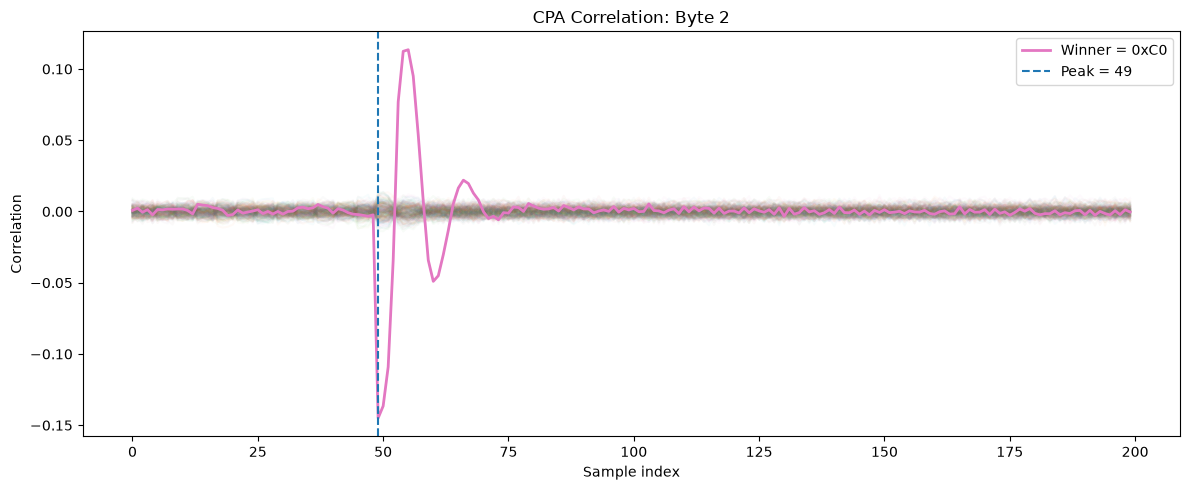

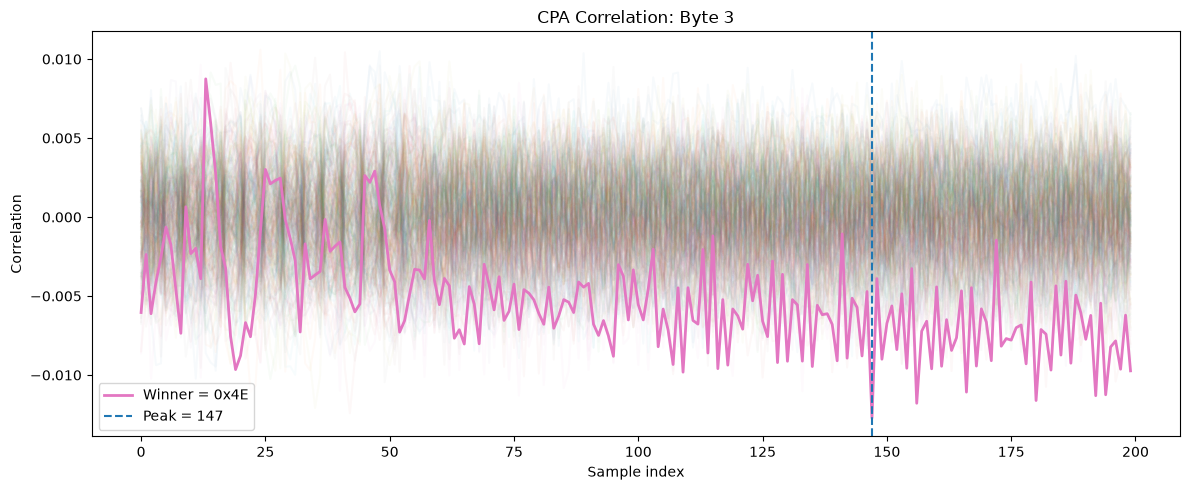

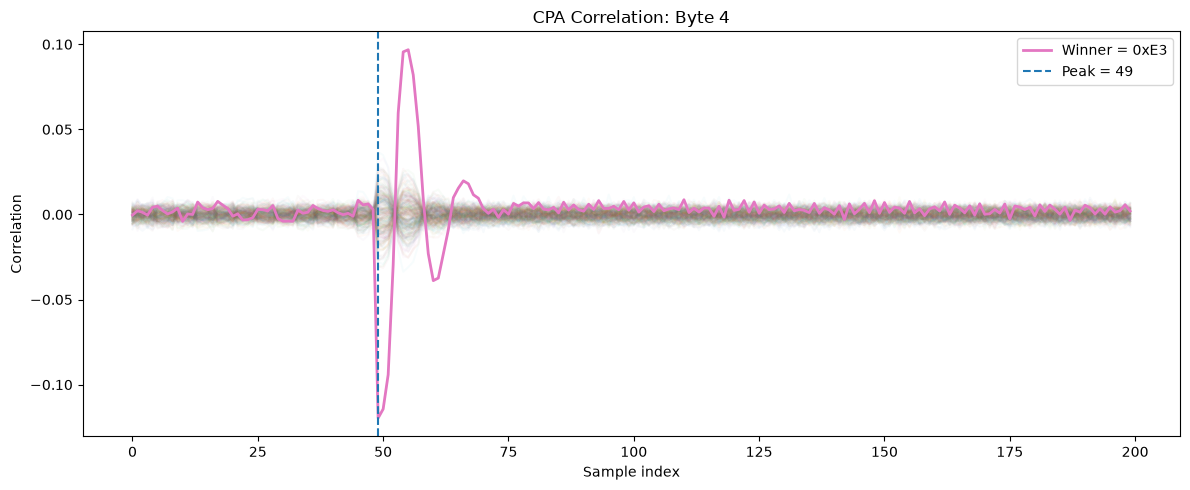

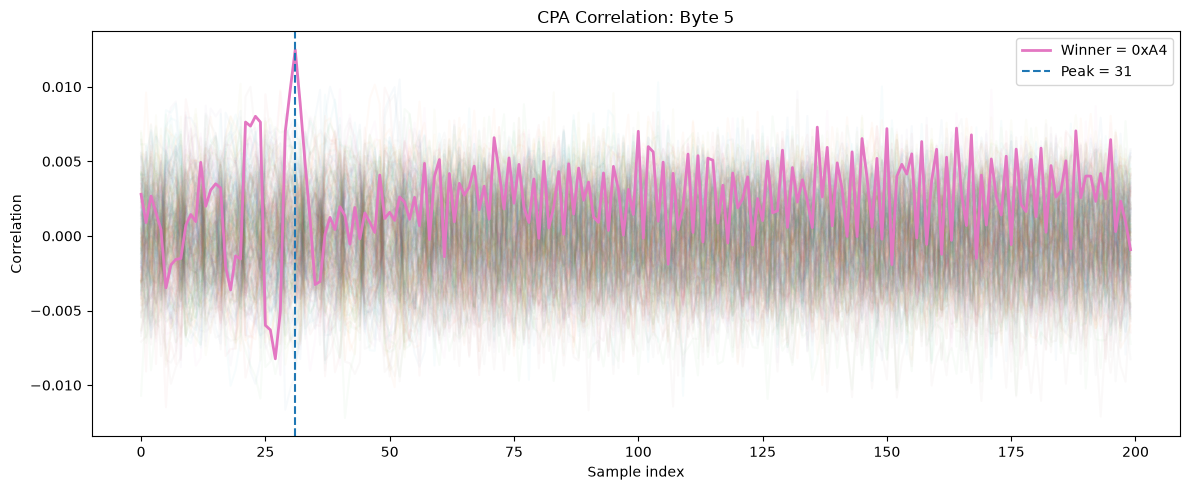

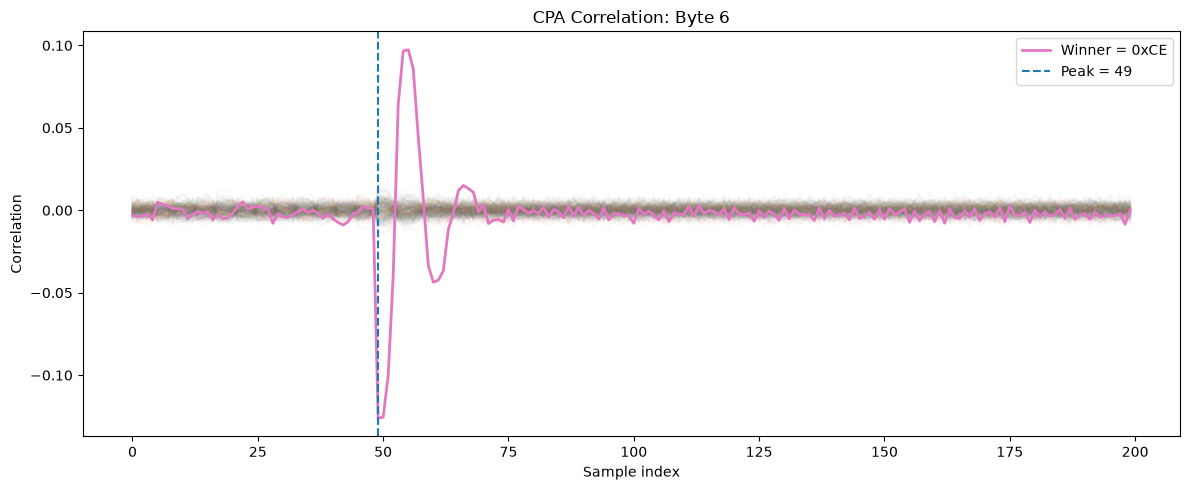

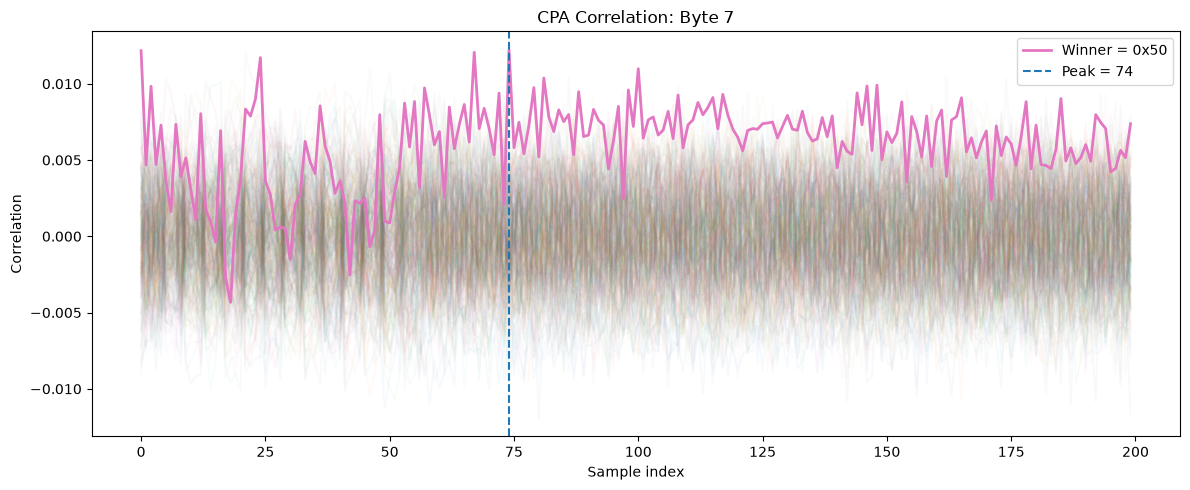

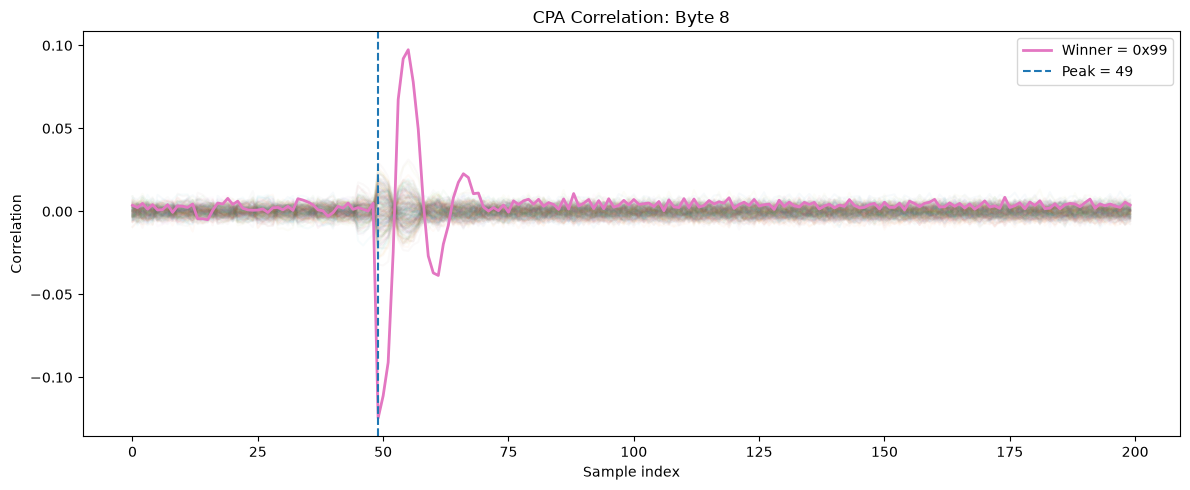

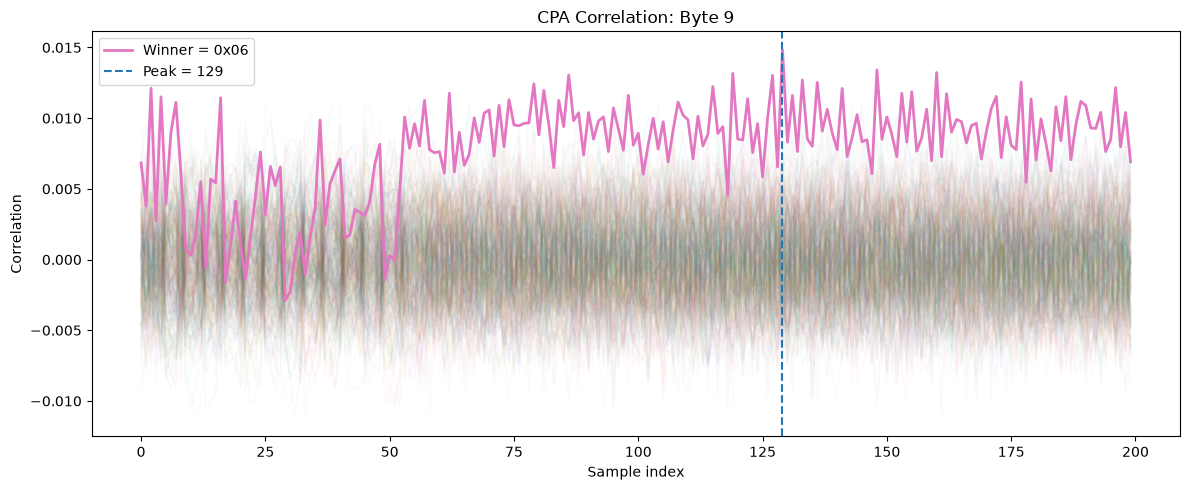

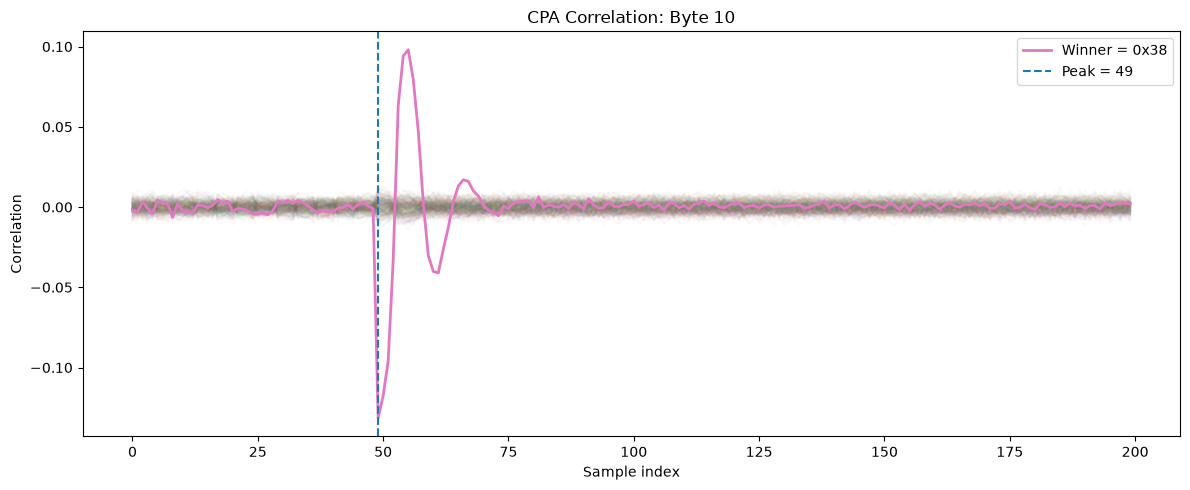

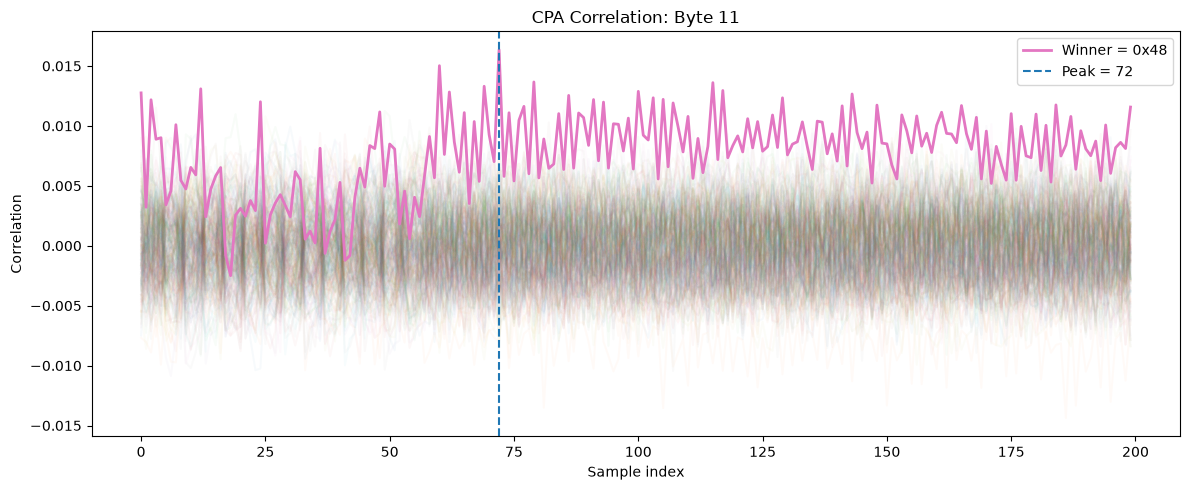

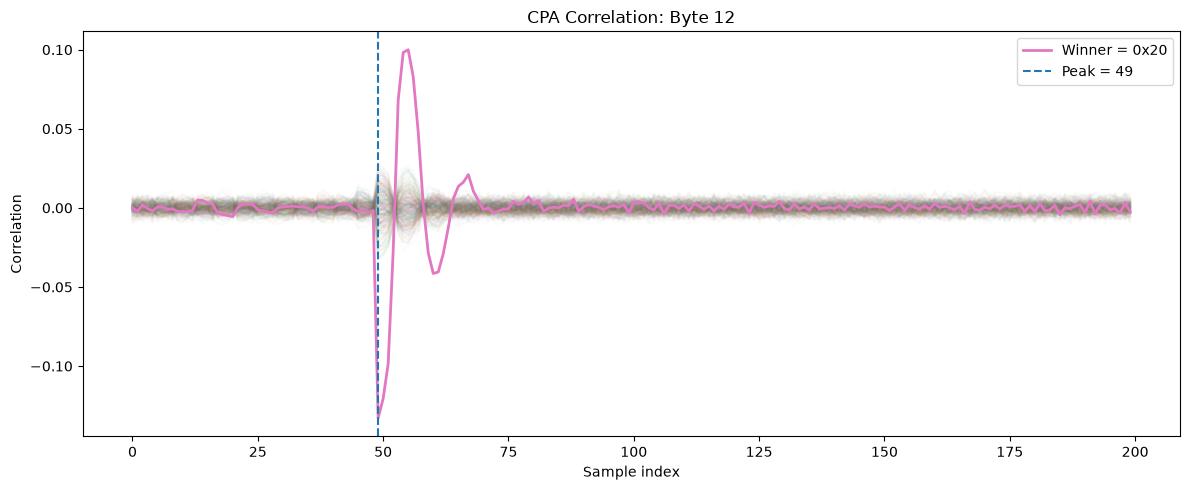

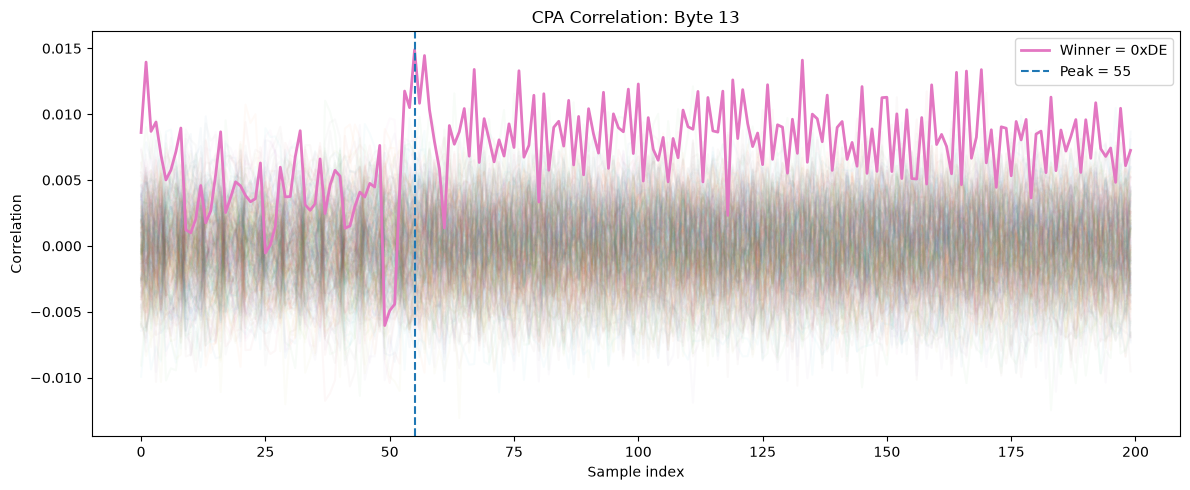

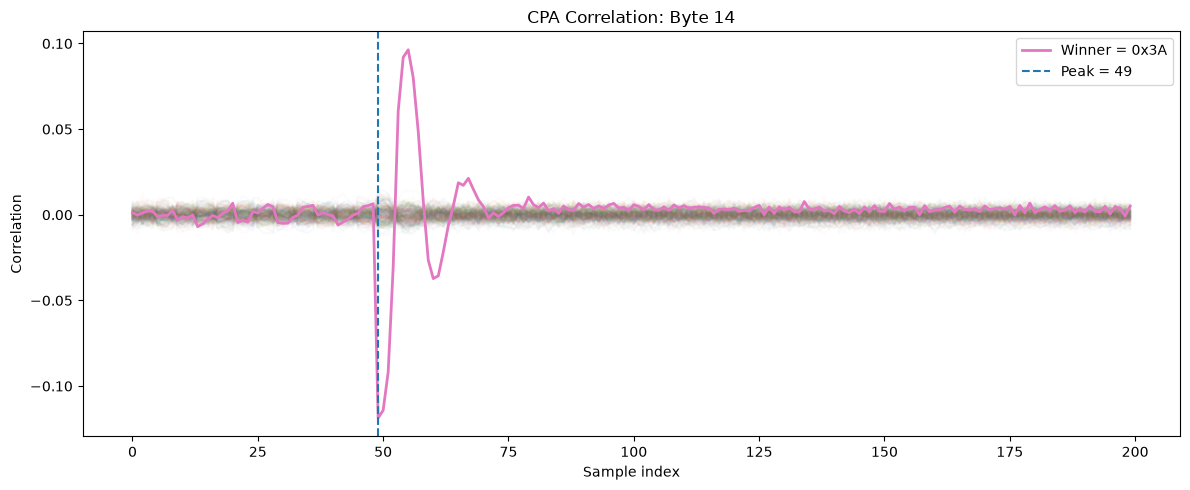

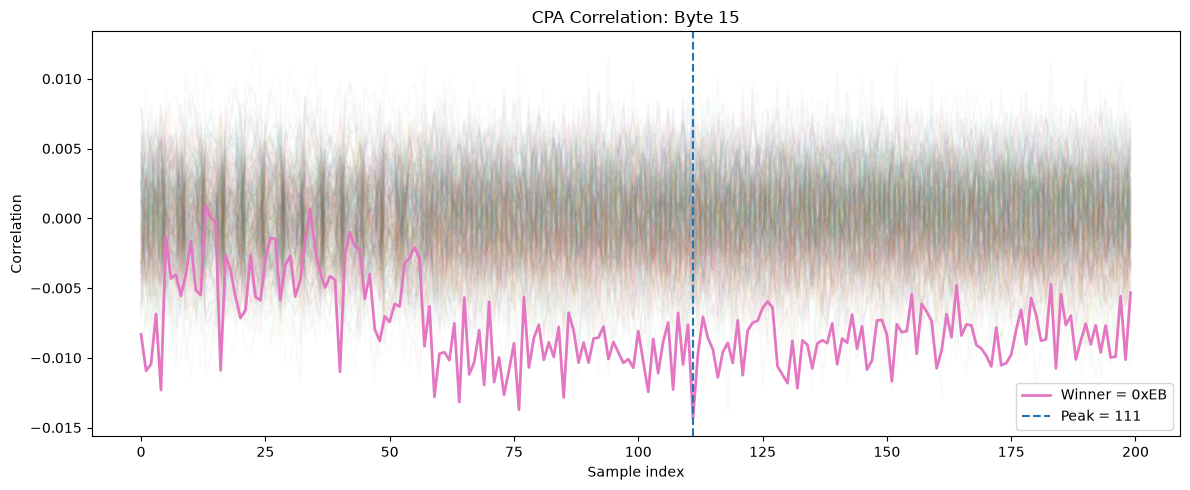

In [12]:
#16 plots
Path(
    "figures/cpa"
).mkdir(
    parents=True,
    exist_ok=True
)

for byte_index in range(16):

    R = correlation_matrices[
        byte_index
    ]

    best_key = results_df.loc[
        byte_index,
        "key"
    ]

    peak_sample = results_df.loc[
        byte_index,
        "peak_sample"
    ]

    plt.figure(figsize=(12, 5))

    for k in range(256):
        plt.plot(
            R[k],
            alpha=0.03
        )

    plt.plot(
        R[best_key],
        linewidth=2,
        label=f"Winner = 0x{best_key:02X}"
    )

    plt.axvline(
        peak_sample,
        linestyle="--",
        label=f"Peak = {peak_sample}"
    )

    plt.xlabel("Sample index")
    plt.ylabel("Correlation")

    plt.title(
        f"CPA Correlation: Byte {byte_index}"
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"figures/cpa/"
        f"byte_{byte_index:02d}.png",
        dpi=200
    )

    plt.show()
    plt.close()

In [20]:

H1 = hypotheses["byte_1"]
R1_check = calculate_cpa(H1, traces)

# Best candidates across all 200 samples
global_scores = np.max(np.abs(R1_check), axis=1)
global_ranked = np.argsort(global_scores)[::-1][:5]

print("Top 5 candidates across all samples:")
for rank, k in enumerate(global_ranked, start=1):
    peak_sample = int(np.argmax(np.abs(R1_check[k])))
    print(
        f"Rank {rank}: 0x{k:02X} | "
        f"|r| = {global_scores[k]:.6f} | "
        f"sample = {peak_sample}"
    )

# Best candidates specifically at sample 49
sample = 49
local_scores = np.abs(R1_check[:, sample])
local_ranked = np.argsort(local_scores)[::-1][:10]

print(f"\nTop 10 candidates at sample {sample}:")
for rank, k in enumerate(local_ranked, start=1):
    print(f"Rank {rank}: 0x{k:02X} | |r| = {local_scores[k]:.6f}")


Top 5 candidates across all samples:
Rank 1: 0x2D | |r| = 0.014437 | sample = 180
Rank 2: 0x9A | |r| = 0.013522 | sample = 125
Rank 3: 0xA9 | |r| = 0.013061 | sample = 10
Rank 4: 0x1A | |r| = 0.012249 | sample = 101
Rank 5: 0xD7 | |r| = 0.012220 | sample = 64

Top 10 candidates at sample 49:
Rank 1: 0x68 | |r| = 0.008887
Rank 2: 0x3D | |r| = 0.008833
Rank 3: 0xFC | |r| = 0.008571
Rank 4: 0x1C | |r| = 0.008039
Rank 5: 0x13 | |r| = 0.008028
Rank 6: 0x21 | |r| = 0.007595
Rank 7: 0x19 | |r| = 0.007431
Rank 8: 0xC4 | |r| = 0.007263
Rank 9: 0xF7 | |r| = 0.007256
Rank 10: 0x59 | |r| = 0.006946


In [26]:

sample = 49

print("Current mapping versus same-byte diagnostic\n")

for byte_index in range(16):
    c_i = ciphertexts[:, byte_index]

    H_current = hypotheses[f"byte_{byte_index}"]
    R_current = calculate_cpa(H_current, traces)
    current_corr = np.max(np.abs(R_current[:, sample]))

    H_same = np.empty((len(ciphertexts), 256), dtype=np.float32)

    for k in range(256):
        intermediate = INV_SBOX[c_i ^ np.uint8(k)]
        H_same[:, k] = HW[intermediate ^ c_i]

    R_same = calculate_cpa(H_same, traces)
    same_corr = np.max(np.abs(R_same[:, sample]))

    print(
        f"Byte {byte_index:2d}: "
        f"current={current_corr:.6f}, "
        f"same-byte={same_corr:.6f}"
    )


Current mapping versus same-byte diagnostic

Byte  0: current=0.132034, same-byte=0.132034
Byte  1: current=0.008887, same-byte=0.017602
Byte  2: current=0.144975, same-byte=0.017391
Byte  3: current=0.010452, same-byte=0.017946
Byte  4: current=0.119641, same-byte=0.119641
Byte  5: current=0.009938, same-byte=0.023737
Byte  6: current=0.126033, same-byte=0.018418
Byte  7: current=0.011237, same-byte=0.020145
Byte  8: current=0.124603, same-byte=0.124603
Byte  9: current=0.010014, same-byte=0.016556
Byte 10: current=0.131500, same-byte=0.022875
Byte 11: current=0.011250, same-byte=0.022866
Byte 12: current=0.132874, same-byte=0.132874
Byte 13: current=0.010198, same-byte=0.024078
Byte 14: current=0.118693, same-byte=0.016225
Byte 15: current=0.010099, same-byte=0.018031
